[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/hyperspectral-course-2026/blob/main/11_preprocessing.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🧹 Preprocessing Hyperspectral Data
### Space Academy 2026 · Hyperspectral course · Week 1 — Preprocessing concepts for hyperspectral data (Lecture + Practical)

Raw pixels are not ready for analysis. Before computing indices, training a classifier or detecting targets, you have
to understand **what the numbers mean**, **which pixels and bands to trust**, and **how to cut the data down** to your
area of interest. This notebook walks through the preprocessing chain for Planet Tanager surface reflectance and finishes
with a reusable `preprocess()` function for your project.

**What you will learn**
- Processing levels: radiance, top-of-atmosphere reflectance and surface reflectance; basic vs ortho products
- What atmospheric correction does, and how to use the water-vapour and aerosol layers delivered with the data
- Quality masks (no-data, cloud, cirrus), and why you must **inspect** them instead of trusting them blindly
- Bad bands: the `good_wavelengths` flag, per-band SNR, residual atmospheric features
- Noise estimation, Savitzky-Golay smoothing, derivatives, continuum removal and band-depth maps
- Negative reflectances over water, illumination and viewing geometry, brightness normalisation
- Spatial preprocessing: windows by lon/lat, previews, shareable subsets, Cloud-Optimised GeoTIFF export and reprojection

**Prerequisites**: `00_EO_data_quickstart_notebook.ipynb`, `10_spectral_signatures_and_libraries.ipynb`. If you are not fluent with numpy arrays (axes, boolean masks, broadcasting), work through **`09_numpy_for_hyperspectral.ipynb`** first — it is 45–60 minutes and uses this same data.

**Data**: Tanager scenes `20250511_074311_00_4001` (Al Dhafra coast, UAE), `20241215_185916_33_4001` (Malibu, USA),
`20250608_091605_90_4001` (Konya, Türkiye) and `20250219_053251_31_4001` (Korba coalfield, India). `hu.get_scene()` uses a
local copy when one exists; otherwise it downloads the ~1 GB HDF5 from Planet's open STAC catalogue.

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


In [1]:
# On Google Colab: upload hsi_utils.py next to this notebook and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio xarray rioxarray requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90

UAE, MALIBU, KONYA, KORBA = ("20250511_074311_00_4001", "20241215_185916_33_4001",
                             "20250608_091605_90_4001", "20250219_053251_31_4001")
OUT = hu.ensure_output_dir("11")

## 1. Processing levels: from photons to surface reflectance

| Level | Quantity | What has been done | Tanager STAC asset |
|---|---|---|---|
| **Radiance** | $L(\lambda)$ in W m⁻² sr⁻¹ µm⁻¹ | calibrated detector counts, as seen *at the satellite* | `basic_radiance_hdf5`, `ortho_radiance_hdf5` |
| **TOA reflectance** | $\rho_{TOA} = \dfrac{\pi L d^2}{E_{sun}(\lambda)\cos\theta_s}$ | radiance normalised by incoming sunlight (sun–Earth distance $d$, solar zenith $\theta_s$) | computed by the user |
| **Surface reflectance** | $\rho_{s}(\lambda)$, 0–1 | atmospheric absorption and scattering removed | `basic_sr_hdf5`, `ortho_sr_hdf5` ← **used in this course** |

- **Basic** products stay in the sensor's viewing geometry; a separate `geolocation_array` gives each pixel's lon/lat.
- **Ortho** products are terrain-corrected and resampled onto a map grid (UTM, 30 m). Use ortho unless you have a
  specific reason not to (e.g. you want to avoid resampling for a physics retrieval).

**Atmospheric correction** is the step from TOA to surface reflectance. The atmosphere does two things:

1. **Absorbs** light: water vapour (strong bands near 940, 1130, 1380 and 1880 nm), O₂ (760 nm), CO₂ (2010, 2060 nm) and CH₄ (2300 nm).
2. **Scatters** light: molecules (Rayleigh, strongest in the blue) and aerosols (haze, dust, smoke). This adds
   *path radiance* and blurs contrasts.

Radiative-transfer codes (e.g. MODTRAN, 6S or the open-source ISOFIT used for NASA's EMIT) model both effects using the
retrieved **column water vapour** and **aerosol optical depth** of every pixel. Tanager delivers those retrievals
as extra layers in the HDF5. Let's look at them, and at the asset list in the STAC item (this cell needs internet and
falls back to a static list offline).

In [2]:
try:
    item = hu.fetch_item(UAE)
    assets = pd.DataFrame([{"asset": k, "type": a.get("type", "").split(";")[0], "roles": ", ".join(a.get("roles", []))}
                           for k, a in item["assets"].items()])
    print("Assets in the STAC item of", UAE)
    display(assets)
except Exception as err:  # offline
    print("Offline — Tanager items contain: basic/ortho radiance HDF5, basic/ortho surface reflectance HDF5,"
          " basic/ortho beta UDM (usable data mask), geolocation array, ortho visual COG and a thumbnail.", err)

Assets in the STAC item of 20250511_074311_00_4001


,asset,type,roles
0,basic_beta_udm,image/tiff,"metadata, cloud, data-mask"
1,basic_radiance_hdf5,application/x-hdf5,"data, metadata, cloud, data-mask"
2,basic_sr_hdf5,application/x-hdf5,"reflectance, data, metadata, cloud, data-mask"
3,geolocation_array,image/tiff,metadata
4,ortho_beta_udm,image/tiff,"metadata, cloud, data-mask"
5,ortho_radiance_hdf5,application/x-hdf5,"data, metadata, cloud, data-mask"
6,ortho_sr_hdf5,application/x-hdf5,"reflectance, data, metadata, cloud, data-mask"
7,ortho_visual,image/tiff,"visual, data"
8,thumbnail,image/png,thumbnail


Scene      : 20250511_074311_00_4001  (Al Dhafra coast, UAE)
File       : /home/course/notebooks/20250511_074311_00_4001_ortho_sr_hdf5.h5
Cube       : 426 bands × 733 rows × 878 cols
Wavelengths: 376–2499 nm, FWHM 5.2–6.8 nm
Good bands : 352 of 426
Grid       : EPSG:32639, 30 m pixels
No-data    : 21.3%   cloud flag: 40.4%   cirrus flag: 0.0%   usable: 38.4%

Fields in the file: ['aerosol_optical_depth', 'beta_cirrus_mask', 'beta_cloud_mask', 'column_water_vapour', 'nodata_pixels', 'sensor_azimuth', 'sensor_to_ground_path_length', 'sensor_zenith', 'sun_azimuth', 'sun_zenith', 'surface_reflectance', 'surface_reflectance_uncertainty', 'time']


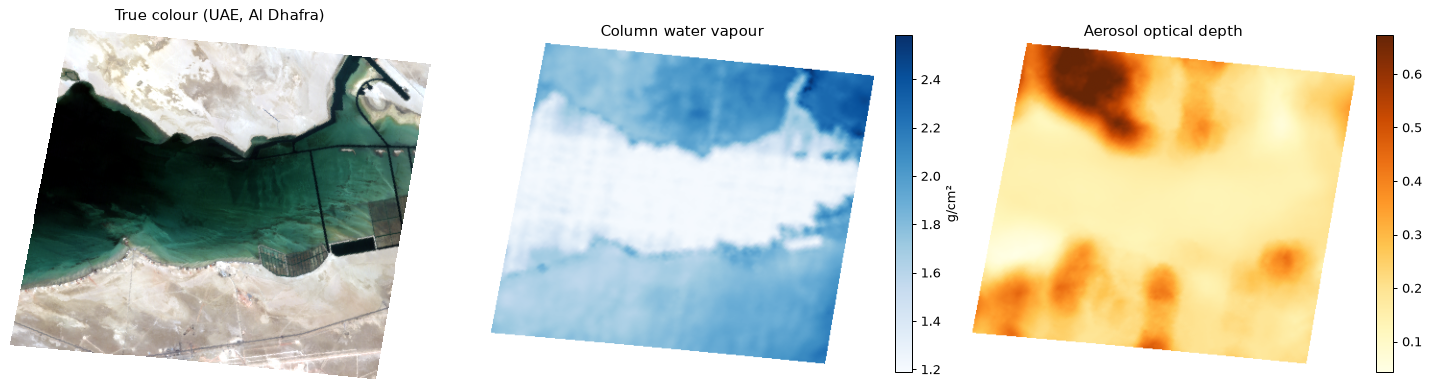

Water vapour: 1.21–2.16 g/cm² (5–95 %),  AOD: 0.12–0.54


In [3]:
uae = hu.get_scene(UAE)
print(uae.summary())
print("\nFields in the file:", uae.field_names)

stride = 2
cwv = uae.read_field("column_water_vapour", stride=stride)
aod = uae.read_field("aerosol_optical_depth", stride=stride)
nodata = uae.masks(stride=stride)["nodata"]
cwv[nodata], aod[nodata] = np.nan, np.nan

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].imshow(uae.rgb(stride=stride, mask=False)); axes[0].set_title("True colour (UAE, Al Dhafra)")
im = axes[1].imshow(cwv, cmap="Blues"); plt.colorbar(im, ax=axes[1], fraction=0.04, label="g/cm²")
axes[1].set_title("Column water vapour")
im = axes[2].imshow(aod, cmap="YlOrBr", vmax=np.nanpercentile(aod, 99)); plt.colorbar(im, ax=axes[2], fraction=0.04)
axes[2].set_title("Aerosol optical depth")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print(f"Water vapour: {np.nanpercentile(cwv, 5):.2f}–{np.nanpercentile(cwv, 95):.2f} g/cm² (5–95 %),"
      f"  AOD: {np.nanpercentile(aod, 5):.2f}–{np.nanpercentile(aod, 95):.2f}")

Water vapour and aerosols vary **within** a single 25 km scene, which is why atmospheric correction is done pixel by pixel.
But look critically: the water-vapour map changes **abruptly at the coastline**. The real atmosphere does not change at
the shore. Dark water returns very little signal in the water-vapour bands, so the retrieval behaves differently there.
Likewise the highest AOD values sit over the brightest sabkha in the north, where separating aerosol from surface
signal is hardest. These layers are **retrievals with their own errors**, and they are useful **quality covariates**
(e.g. "is my index anomaly correlated with AOD, or does it follow the coastline?").

**Did the correction work?** A check: after correction, the depth of the 1130 nm water-vapour feature over land
should be small and should *not* depend on the column water vapour. If it grew with water vapour, the correction would
have left water-vapour signal in the reflectance.

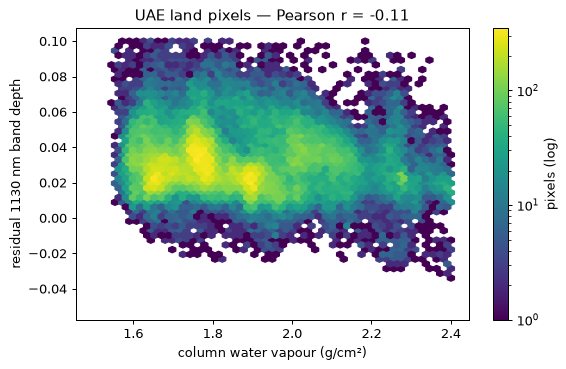

Median residual depth: 0.030


In [4]:
b = lambda w: uae.read_band(w, stride=stride, cloud=False)
d1130 = 1 - b(1135) / ((b(1080) + b(1190)) / 2)          # residual water-vapour feature depth
land = hu.nd(b(560), b(860)) < 0
ok = land & np.isfinite(d1130) & np.isfinite(cwv)
r = np.corrcoef(cwv[ok], d1130[ok])[0, 1]

fig, ax = plt.subplots(figsize=(6.5, 4.2))
hb = ax.hexbin(cwv[ok], d1130[ok], gridsize=50, bins="log", cmap="viridis", extent=(1.5, 2.4, -0.05, 0.1))
plt.colorbar(hb, label="pixels (log)")
ax.set_xlabel("column water vapour (g/cm²)"); ax.set_ylabel("residual 1130 nm band depth")
ax.set_title(f"UAE land pixels — Pearson r = {r:.2f}")
plt.tight_layout(); plt.show()
print(f"Median residual depth: {np.nanmedian(d1130[ok]):.3f}")

The residual feature is small (a few % of the signal) and hardly related to water vapour: the correction removed the
pixel-to-pixel water-vapour variation. What remains is a small, systematic residual. You will see it as a little dip
near 1130 nm (and 940 nm) in most spectra. Know it is there and don't interpret it as a surface feature.

## 2. Quality masks: inspect before you trust

Each Tanager file has three quality layers:

| Layer | Meaning |
|---|---|
| `nodata_pixels` | outside the imaged footprint (the rotated strip leaves ~20–30 % of the grid empty) |
| `beta_cloud_mask` | cloud, from Planet's *beta* cloud classifier |
| `beta_cirrus_mask` | thin high cirrus |

`hu.TanagerScene.valid_mask()` combines them. The word **beta** matters: these masks are experimental. On a perfectly
clear day, the UAE scene flags **~40 % of its grid, about half of all valid pixels, as cloud**. Let's see where.

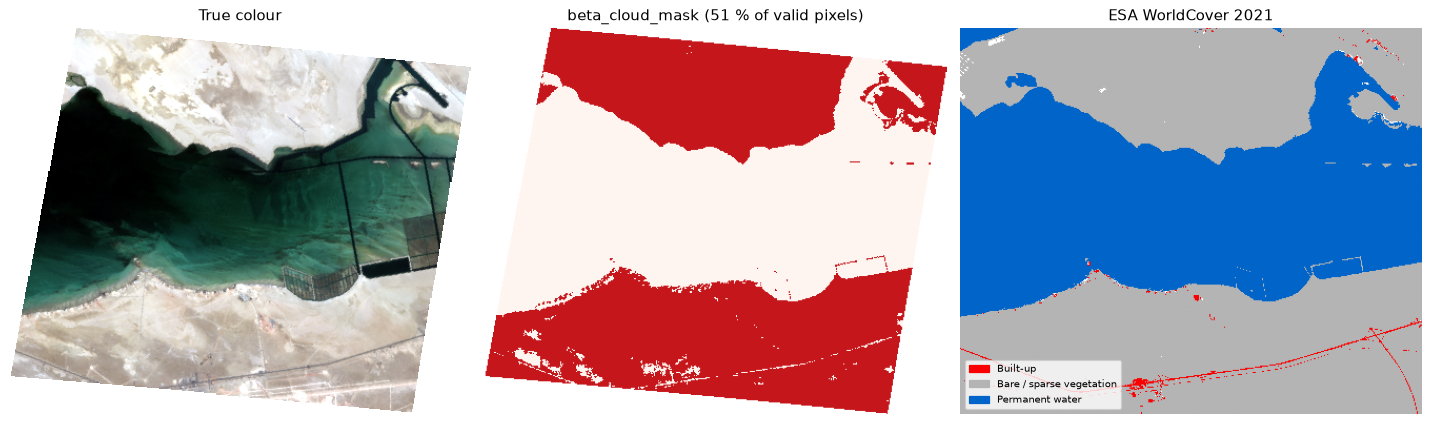

Bare / sparse vegetation :  97.1 % flagged as cloud
Permanent water          :   2.2 % flagged as cloud
Built-up                 :  63.2 % flagged as cloud


In [5]:
m = uae.masks(stride=stride)
lab, _ = hu.load_labels(UAE)
lab = lab[::stride, ::stride]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].imshow(uae.rgb(stride=stride, mask=False)); axes[0].set_title("True colour")
axes[1].imshow(np.where(m["nodata"], np.nan, m["cloud"]), cmap="Reds", vmin=0, vmax=1.3)
axes[1].set_title(f"beta_cloud_mask ({m['cloud'][~m['nodata']].mean() * 100:.0f} % of valid pixels)")
cmap, norm, handles = hu.label_cmap([60, 80, 50])
axes[2].imshow(np.where(np.isin(lab, [50, 60, 80]), lab, np.nan), cmap=cmap, norm=norm)
axes[2].legend(handles=handles, fontsize=8, loc="lower left"); axes[2].set_title("ESA WorldCover 2021")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

valid = ~m["nodata"]
for code in [60, 80, 50]:
    sel = valid & (lab == code)
    print(f"{hu.WORLDCOVER_CLASSES[code][0]:25s}: {m['cloud'][sel].mean() * 100:5.1f} % flagged as cloud")

Almost all bare land (**bright sabkha and desert**) is flagged as cloud, and the water is not. Bright, white surfaces
are the classic failure mode of cloud detectors. The opposite error exists too. The Malibu scene (15 Dec 2024) has
thin clouds over the ocean that the mask **misses**. Compare the spectra:

Malibu cloud flag: 36 pixels flagged in the whole scene


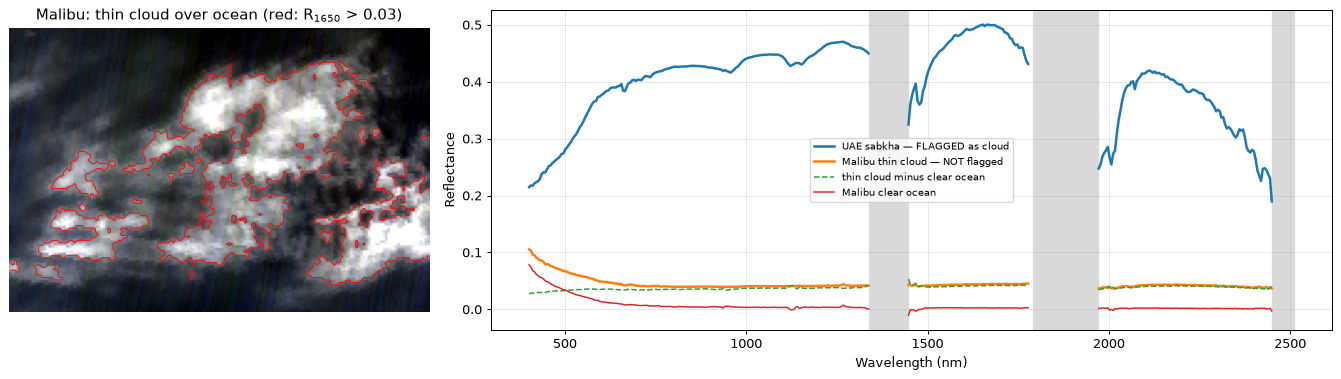

In [6]:
malibu = hu.get_scene(MALIBU)
print("Malibu cloud flag:", malibu.masks()["cloud"].sum(), "pixels flagged in the whole scene")

# thin cloud window over the ocean (visible in the true-colour image) and a clear-ocean window
cw, ow = (430, 545, 140, 310), (560, 700, 300, 500)
cloud_cube, wl = malibu.read_cube(cw, cloud=False)
ocean_cube, _ = malibu.read_cube(ow, cloud=False)
r1650 = cloud_cube[hu.band_index(wl, 1650)]
thin_cloud = np.nanmedian(cloud_cube[:, r1650 > 0.03], axis=1)
clear_ocean = np.nanmedian(ocean_cube.reshape(len(wl), -1), axis=1)

sab_cube, wl_u = uae.read_cube((550, 650, 300, 450), cloud=False)
sab_flag = uae.masks((550, 650, 300, 450))["cloud"]
flagged_sabkha = np.nanmedian(sab_cube[:, sab_flag], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1, 2]})
axes[0].imshow(hu.rgb_from_cube(cloud_cube, wl)); axes[0].contour(r1650 > 0.03, levels=[0.5], colors="r", linewidths=0.7)
axes[0].set_title("Malibu: thin cloud over ocean (red: R$_{1650}$ > 0.03)"); axes[0].axis("off")
ax = axes[1]; hu.shade_bad_regions(ax)
hu.plot_spectrum(ax, wl_u, flagged_sabkha, lw=2, label="UAE sabkha — FLAGGED as cloud")
hu.plot_spectrum(ax, wl, thin_cloud, lw=2, label="Malibu thin cloud — NOT flagged")
hu.plot_spectrum(ax, wl, thin_cloud - clear_ocean, lw=1.2, ls="--", label="thin cloud minus clear ocean")
hu.plot_spectrum(ax, wl, clear_ocean, lw=1.2, label="Malibu clear ocean")
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Reflectance"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

- The **flagged sabkha** has a real mineral spectrum: a rising visible slope, SWIR structure and a carbonate feature
  (notebook 10). Clouds are spectrally much flatter.
- The **thin cloud** adds an almost *flat* offset to the dark ocean (dashed line), including in the SWIR, where clear water
  is essentially black. That makes SWIR reflectance an excellent **cloud and glint test over water**.

Let's build that test for the whole Malibu scene:

Water pixels flagged by the SWIR test: 16,682  (beta_cloud_mask: 36 in the whole scene)


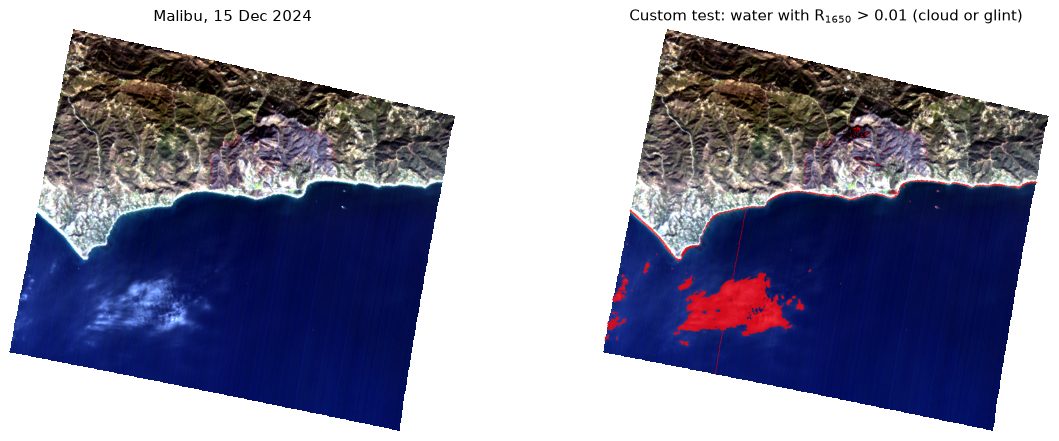

In [7]:
g, n, s = (malibu.read_band(w, cloud=False) for w in (560, 860, 1650))
water = hu.nd(g, n) > 0
my_cloud = water & (s > 0.01)       # clear water is < ~0.005 at 1650 nm
print(f"Water pixels flagged by the SWIR test: {my_cloud.sum():,}  "
      f"(beta_cloud_mask: {malibu.masks()['cloud'].sum():,} in the whole scene)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(malibu.rgb(mask=False)); axes[0].set_title("Malibu, 15 Dec 2024")
axes[1].imshow(malibu.rgb(mask=False)); axes[1].imshow(np.where(my_cloud, 1, np.nan), cmap="autumn", alpha=0.8)
axes[1].set_title("Custom test: water with R$_{1650}$ > 0.01 (cloud or glint)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

The test finds the thin cloud, and two other things worth noticing:

- the **surf zone** along the coast, where breaking waves and very shallow water are bright in the SWIR. A real mask
  would add a coastal buffer or require a minimum distance from land;
- a thin **vertical line** in the ocean: a *detector stripe*. Pushbroom imagers such as Tanager record each image
  column with a different detector element, and a slightly mis-calibrated element leaves a stripe. Faint stripes are
  also visible in the true-colour ocean. You can only see such artefacts over very uniform, dark surfaces.

> ✅ **Lesson.** Always *look* at the masks on top of an RGB image before using them. Decide per scene whether to use
> them as-is (`cloud=True`), ignore them (`cloud=False`, e.g. for the UAE scene) or build a better rule for your target.
> Write that decision down in your project report.

## 3. Bad bands

### 3.1 The `good_wavelengths` flag and placeholder values

The HDF5 stores a per-band `good_wavelengths` flag (0 = unusable) for the deep water-vapour absorptions at
~1340–1440 and ~1780–1970 nm. In the *core* of those ranges the file contains a **constant placeholder (−0.01)**, not a
measurement. At the *edges* of the flagged ranges there are real-looking values, but they are unreliable.

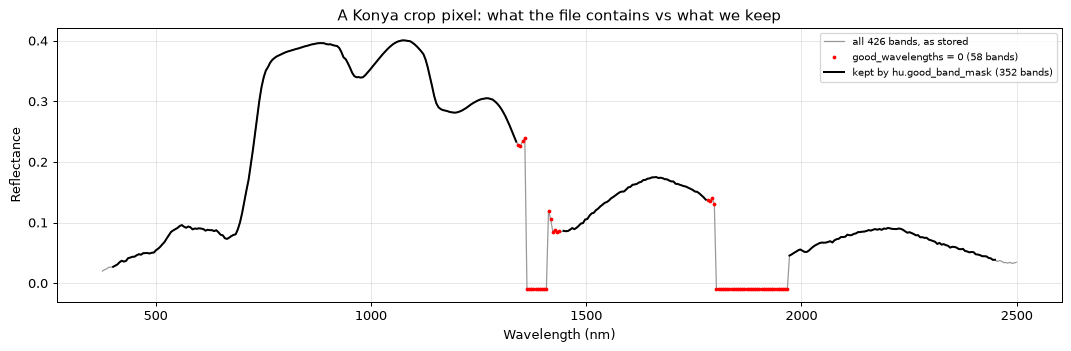

Most common value in flagged bands: -0.010 (44 of 58 bands)


In [8]:
konya = hu.get_scene(KONYA)
spec_all, wl_all = konya.read_pixel(237, 560, bands="all")     # an irrigated field
flag = konya.file_good_flags

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(wl_all, spec_all, color="0.6", lw=1, label="all 426 bands, as stored")
ax.plot(wl_all[~flag], spec_all[~flag], "r.", ms=4, label=f"good_wavelengths = 0 ({(~flag).sum()} bands)")
hu.plot_spectrum(ax, konya.wavelengths[konya.good_bands], spec_all[konya.good_bands], color="k", lw=1.6,
                 label=f"kept by hu.good_band_mask ({konya.good_bands.sum()} bands)")
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Reflectance"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax.set_title("A Konya crop pixel: what the file contains vs what we keep")
plt.tight_layout(); plt.show()
vals, counts = np.unique(np.round(spec_all[~flag], 4), return_counts=True)
print(f"Most common value in flagged bands: {vals[np.argmax(counts)]:.3f} ({counts.max()} of {(~flag).sum()} bands)")

### 3.2 Signal-to-noise per band

Beyond the flagged bands, we also drop the ends of the spectrum. The `surface_reflectance_uncertainty` layer gives a
per-band SNR (reflectance ÷ uncertainty). Over a bright field in Konya:

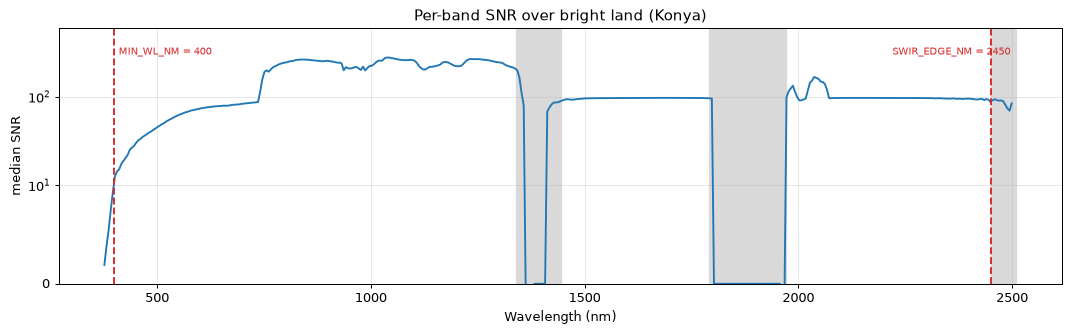

SNR below 400 nm: [1.9 3.8 5.4 7.5 9.3]


In [9]:
win = (250, 330, 350, 430)
refl, w = konya.read_cube(win, bands="all")
unc, _ = konya.read_cube(win, bands="all", dataset="surface_reflectance_uncertainty")
snr = np.nanmedian((refl / unc).reshape(len(w), -1), axis=1)

fig, ax = plt.subplots(figsize=(12, 3.8))
hu.shade_bad_regions(ax)
ax.plot(w, snr, lw=1.5)
ax.axvline(hu.MIN_WL_NM, color="C3", ls="--"); ax.axvline(hu.SWIR_EDGE_NM, color="C3", ls="--")
ax.text(hu.MIN_WL_NM + 10, 300, f"MIN_WL_NM = {hu.MIN_WL_NM:.0f}", color="C3", fontsize=8)
ax.text(hu.SWIR_EDGE_NM - 230, 300, f"SWIR_EDGE_NM = {hu.SWIR_EDGE_NM:.0f}", color="C3", fontsize=8)
ax.set_yscale("symlog", linthresh=10); ax.set_ylim(0, 600)
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("median SNR"); ax.grid(alpha=0.3)
ax.set_title("Per-band SNR over bright land (Konya)")
plt.tight_layout(); plt.show()
print("SNR below 400 nm:", np.round(snr[w < 400], 1))

- **Below 400 nm** the SNR falls below ~10: little ultraviolet light reaches the ground, and Rayleigh scattering is
  strongest there. `hu.MIN_WL_NM = 400` removes these bands.
- **Beyond 2450 nm** the SNR looks fine in the uncertainty layer, but real spectra become erratic (spikes, see the
  library in notebook 10): the atmospheric window is closing and the detector's edge channels are least reliable.
  `hu.SWIR_EDGE_NM = 2450` removes them.
- **At the edges of the water-vapour windows** the SNR drops steeply. `hu.WATER_VAPOUR_NM` removes a few bands more
  than the file flag does.

These defaults are what `scene.read_cube(bands="good")` and `hu.good_band_mask()` apply. For some applications you
may want to be stricter. Water studies, for example, often drop everything beyond ~1000 nm (section 6).

### 3.3 Residual atmospheric features

Continuum removal (notebook 10) on a smooth, bright target exposes what the atmospheric correction left behind:

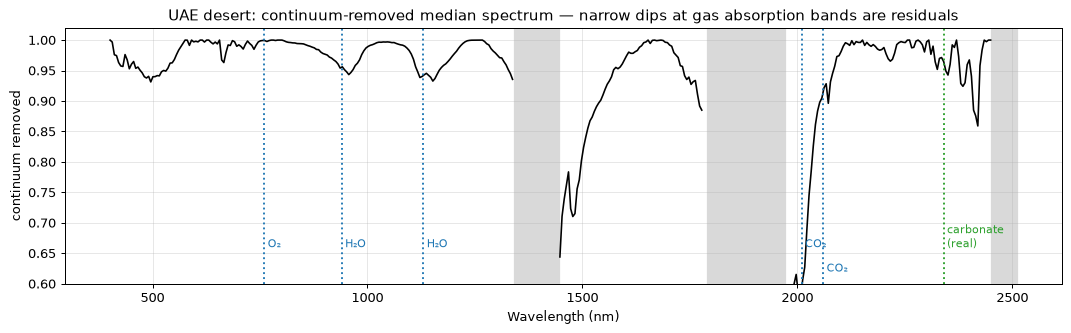

In [10]:
desert, wl_d = uae.read_cube((600, 660, 300, 420), cloud=False)
d_spec = np.nanmedian(desert.reshape(len(wl_d), -1), axis=1)
cr = hu.continuum_removed(wl_d, d_spec)

fig, ax = plt.subplots(figsize=(12, 3.8))
hu.shade_bad_regions(ax)
hu.plot_spectrum(ax, wl_d, cr, lw=1.3, color="k")
for x, lab_, y in [(760, "O₂", 0.66), (940, "H₂O", 0.66), (1130, "H₂O", 0.66), (2010, "CO₂", 0.66), (2060, "CO₂", 0.62),
                   (2340, "carbonate\n(real)", 0.66)]:
    ax.axvline(x, color="C0" if "real" not in lab_ else "C2", ls=":")
    ax.text(x + 8, y, lab_, color="C0" if "real" not in lab_ else "C2", fontsize=9)
ax.set_ylim(0.6, 1.02); ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("continuum removed")
ax.set_title("UAE desert: continuum-removed median spectrum — narrow dips at gas absorption bands are residuals")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

How to read this:

- Narrow dips that line up with **gas absorption bands**, such as the small O₂ dip at 760 nm and the H₂O dip at 1130 nm,
  are residuals, not geology.
- The 940 nm dip overlaps the **iron-oxide** band of the sand (notebook 10), so here residual and real signal mix.
- The steep drops right next to the removed windows (1450–1500 nm and 2000–2060 nm, where CO₂ also absorbs) are the
  **strongest residuals**. Treat features there with great caution.
- The broader features beyond 2300 nm include the real **carbonate** band of the desert sand.

If a residual interferes with your index, move the index's bands away from it, or add the range to `extra_bad` in
`hu.good_band_mask`.

## 4. How noisy are the data? Two noise estimates

1. **Uncertainty layer**: the provider's per-pixel, per-band uncertainty estimate.
2. **Shift difference**: in a *homogeneous* area, neighbouring pixels differ mainly because of noise, so
   $\sigma_{noise} \approx 1.4826\,\mathrm{MAD}(x_{i+1}-x_i)/\sqrt{2}$ (MAD = median absolute deviation, a robust spread).
   Over textured areas (fields, cities) this *over*-estimates noise because real spatial variation is included.

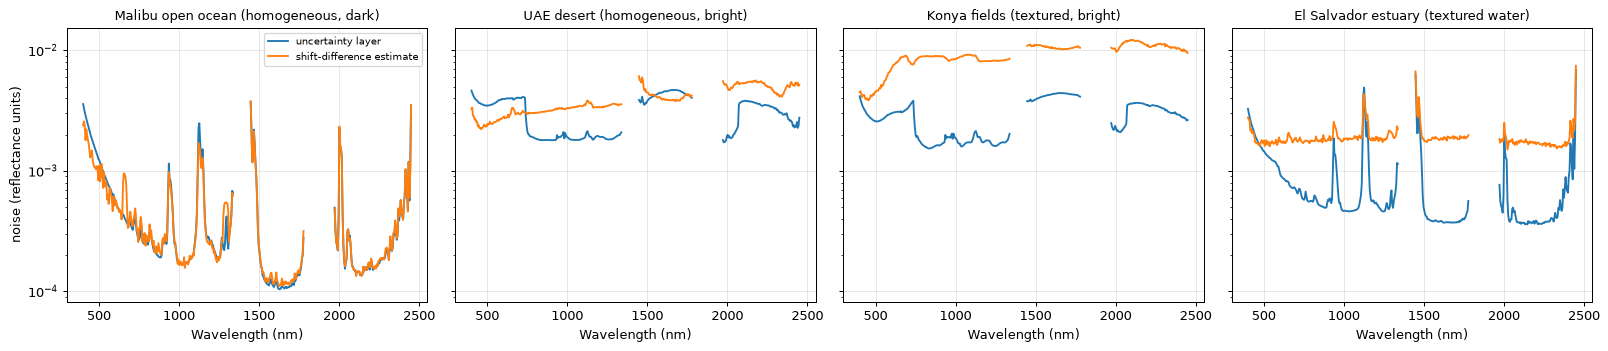

In [11]:
def shift_difference_noise(cube):
    d = cube[:, :, 1:] - cube[:, :, :-1]
    mad = np.nanmedian(np.abs(d - np.nanmedian(d, axis=(1, 2), keepdims=True)), axis=(1, 2))
    return 1.4826 * mad / np.sqrt(2)

cases = {
    "Malibu open ocean (homogeneous, dark)": (malibu, (600, 660, 350, 450)),
    "UAE desert (homogeneous, bright)": (uae, (600, 660, 300, 420)),
    "Konya fields (textured, bright)": (konya, (250, 330, 350, 430)),
    "El Salvador estuary (textured water)": (hu.get_scene("20250223_165546_32_4001"), (560, 600, 400, 440)),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (name, (sc, wn)) in zip(axes, cases.items()):
    refl, w = sc.read_cube(wn, cloud=False)
    unc, _ = sc.read_cube(wn, cloud=False, dataset="surface_reflectance_uncertainty")
    hu.plot_spectrum(ax, w, np.nanmedian(unc.reshape(len(w), -1), axis=1), label="uncertainty layer")
    hu.plot_spectrum(ax, w, shift_difference_noise(refl), label="shift-difference estimate")
    ax.set_yscale("log"); ax.set_title(name, fontsize=10); ax.set_xlabel("Wavelength (nm)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("noise (reflectance units)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

- Over the **homogeneous open ocean** both estimates agree closely: the uncertainty layer is a realistic noise
  estimate. Note how small the noise is in absolute terms (~0.0002 reflectance), and also how small the signal is,
  so the SNR of dark water is only ~10–25 in the NIR/SWIR.
- Over **homogeneous desert** they agree to within a factor of about two.
- Over **textured targets** (Konya fields, the El Salvador estuary with its sediment plumes) the shift-difference
  estimate is several times larger, because real spatial variation is counted as "noise".

> Rule of thumb: validate the uncertainty layer with a shift-difference estimate on a *homogeneous* patch of your
> target, and never estimate noise on a textured area. The MNF transform in notebook 13 uses exactly this
> shift-difference idea.

## 5. Smoothing, derivatives and continuum removal

### 5.1 Savitzky-Golay smoothing, done correctly

A **Savitzky-Golay (SG) filter** fits a low-order polynomial in a moving window along the spectrum. It reduces noise
while keeping the position and shape of features better than a moving average (Savitzky & Golay, 1964). Two
practical traps:

1. **Never smooth across gaps** where bands were removed: 1335 nm and 1450 nm are not neighbours. Filter each
   contiguous segment separately.
2. `scipy.signal.savgol_filter` fails on `NaN`. Masked pixels need temporary filling.

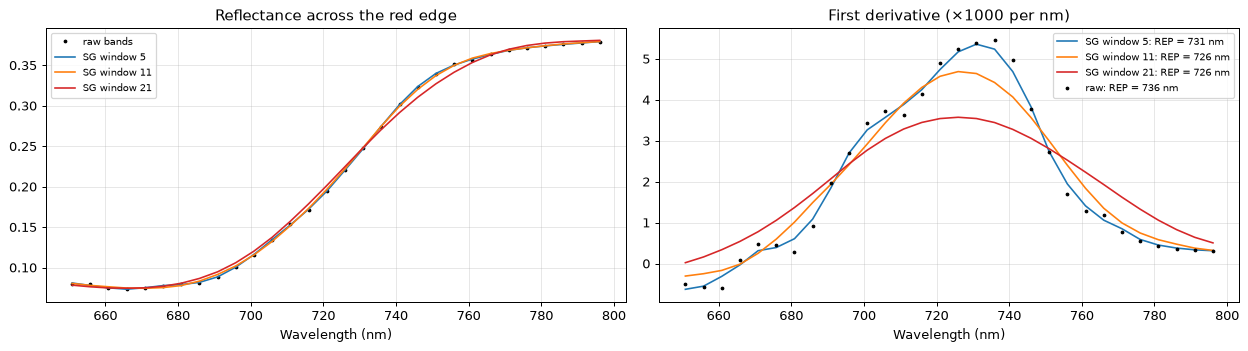

In [12]:
def savgol_segments(cube, wl, window=7, order=2, deriv=0, gap_nm=20.0):
    # Savitzky-Golay along the band axis (axis 0), separately for each contiguous run of bands.
    # Works on 1-D spectra and on (bands, rows, cols) cubes; NaN pixels stay NaN.
    x = np.asarray(cube, dtype="float32")
    out = np.full_like(x, np.nan)
    bad = ~np.isfinite(x)
    filled = np.where(bad, 0.0, x)
    step = float(np.median(np.diff(wl)))
    edges = np.concatenate([[0], np.where(np.diff(wl) > gap_nm)[0] + 1, [len(wl)]])
    for a, b in zip(edges[:-1], edges[1:]):
        if b - a > window:
            out[a:b] = savgol_filter(filled[a:b], window, order, deriv=deriv, delta=step, axis=0)
    out[bad] = np.nan
    return out

# a single crop pixel: raw vs smoothed reflectance and first derivative across the red edge
spec, w = konya.read_pixel(237, 560)
m = (w > 650) & (w < 800)
d_raw = np.gradient(spec, w)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(w[m], spec[m], "k.", ms=4, label="raw bands")
for win_len, col in [(5, "C0"), (11, "C1"), (21, "C3")]:
    axes[0].plot(w[m], savgol_segments(spec, w, win_len)[m], color=col, lw=1.3, label=f"SG window {win_len}")
    d = savgol_segments(spec, w, win_len, deriv=1)
    axes[1].plot(w[m], d[m] * 1000, color=col, lw=1.3,
                 label=f"SG window {win_len}: REP = {w[m][np.nanargmax(d[m])]:.0f} nm")
axes[1].plot(w[m], d_raw[m] * 1000, "k.", ms=4, label=f"raw: REP = {w[m][np.nanargmax(d_raw[m])]:.0f} nm")
axes[0].set_title("Reflectance across the red edge"); axes[1].set_title("First derivative (×1000 per nm)")
for ax in axes: ax.set_xlabel("Wavelength (nm)"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Derivatives amplify noise, so derivative-based products such as the **red-edge position (REP)** benefit from
smoothing. Too large a window flattens and shifts features, so compare several windows and choose the smallest one that
gives stable results. With ~5 nm sampling, 5–11 bands (25–55 nm) is a sensible range.

### 5.2 Band-depth maps

Continuum removal turns absorption features into comparable depths (notebook 10). Applied pixel by pixel, a band depth
becomes a **mineral map**. Here is the Al–OH (clay, ~2205 nm) depth over the Korba coal mines, with and without smoothing:

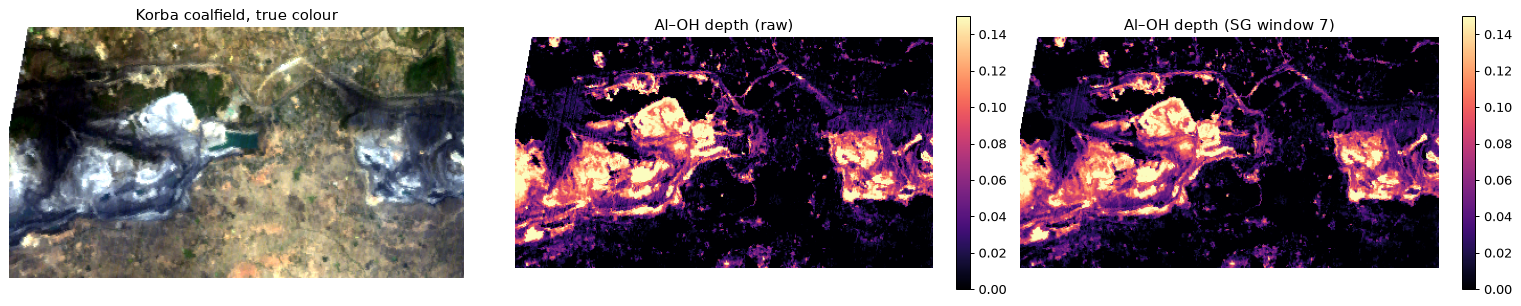

raw      : pixel-to-pixel noise of the depth map = 0.0140
smoothed : pixel-to-pixel noise of the depth map = 0.0123


In [13]:
korba = hu.get_scene(KORBA)
kwin = (480, 700, 50, 450)
kcube, kwl = korba.read_cube(kwin)
depth_raw = hu.band_depth(kwl, kcube, 2120, 2205, 2250)
depth_sg = hu.band_depth(kwl, savgol_segments(kcube, kwl, 7), 2120, 2205, 2250)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].imshow(hu.rgb_from_cube(kcube, kwl)); axes[0].set_title("Korba coalfield, true colour")
for ax, d, t in [(axes[1], depth_raw, "Al–OH depth (raw)"), (axes[2], depth_sg, "Al–OH depth (SG window 7)")]:
    im = ax.imshow(d, cmap="magma", vmin=0, vmax=0.15); ax.set_title(t)
    plt.colorbar(im, ax=ax, fraction=0.03)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

# noise in the map: pixel-to-pixel differences over a uniform area of fields
flat = (150, 210, 250, 350)
for name, d in [("raw", depth_raw), ("smoothed", depth_sg)]:
    patch = d[flat[0]:flat[1], flat[2]:flat[3]]
    print(f"{name:9s}: pixel-to-pixel noise of the depth map = {np.nanstd(np.diff(patch, axis=1)) / np.sqrt(2):.4f}")

The clay-bearing overburden and pit walls of the open-cast mines light up, while the surrounding fields and forest stay
dark. Here smoothing reduces the pixel-to-pixel variation of the map only modestly. Tanager's SNR is high over these
bright surfaces, and much of the remaining variation between neighbouring field pixels is real. Smoothing matters more
for dark targets, weak features and derivatives, as in exercise 2.

## 6. Negative reflectances over water

Surface reflectance cannot physically be negative, yet you will find negative values, mostly over **dark water** at
wavelengths where the signal is close to zero. Noise and a slight over-correction of path radiance push some values
below zero. Many scripts simply set `reflectance < 0` to `NaN`. Let's see what that does over the clear ocean off Malibu.

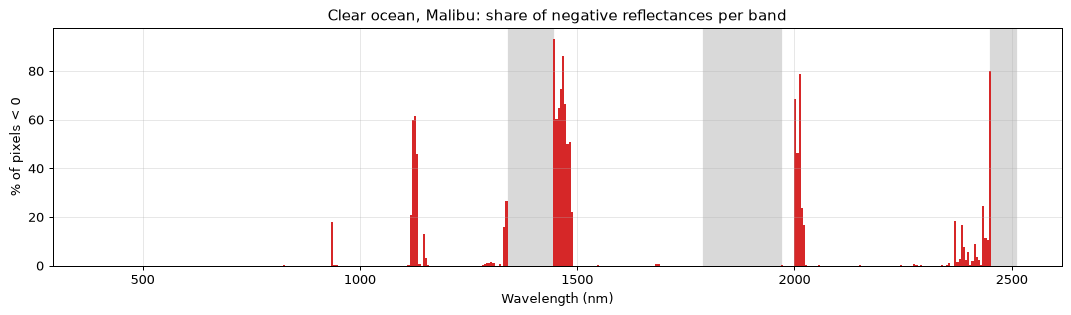

Bands with >10 % negative values: 28  (worst: 1448 nm, 1468 nm, 2449 nm, 2012 nm, 1463 nm)
Complete water spectra: 100 % before, 0 % after setting negatives to NaN
Mean reflectance at 2012 nm: -0.0019 with negatives kept, 0.0016 with negatives removed (biased high)


In [14]:
ocean, wl_o = malibu.read_cube(ow, cloud=False)
X = ocean.reshape(len(wl_o), -1)
X = X[:, np.all(np.isfinite(X), axis=0)]      # valid ocean pixels only (drop the no-data corner of the window)
neg_frac = np.mean(X < 0, axis=1)

fig, ax = plt.subplots(figsize=(12, 3.6))
hu.shade_bad_regions(ax)
ax.bar(wl_o, neg_frac * 100, width=5, color="C3")
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("% of pixels < 0"); ax.grid(alpha=0.3)
ax.set_title("Clear ocean, Malibu: share of negative reflectances per band")
plt.tight_layout(); plt.show()

complete_before = np.all(np.isfinite(X), axis=0).mean()
complete_after = np.all(np.isfinite(np.where(X < 0, np.nan, X)), axis=0).mean()
i = hu.band_index(wl_o, 2012)
print(f"Bands with >10 % negative values: {(neg_frac > 0.1).sum()}  (worst: "
      + ", ".join(f"{wl_o[j]:.0f} nm" for j in np.argsort(neg_frac)[::-1][:5]) + ")")
print(f"Complete water spectra: {complete_before * 100:.0f} % before, {complete_after * 100:.0f} % after setting negatives to NaN")
print(f"Mean reflectance at {wl_o[i]:.0f} nm: {np.nanmean(X[i]):.4f} with negatives kept, "
      f"{np.nanmean(np.where(X[i] < 0, np.nan, X[i])):.4f} with negatives removed (biased high)")

Negative values cluster at the **edges of absorption windows** (≈1120, 1450–1480, 2000–2015, 2450 nm), where almost no
signal reaches the sensor. Setting them to `NaN` would

- make almost every water spectrum incomplete, so `hu.cube_to_pixels` would drop it and PCA or classifiers would lose all water;
- **bias** averages upward, since only the positive half of the noise survives.

Better options: **keep them** (noise is symmetric, and averages stay unbiased); **drop the offending bands** for water work
(`hu.good_band_mask(wl, extra_bad=((1440, 1490), (1995, 2020)))`, or ignore everything beyond ~1000 nm); and clip to 0
only at the very end, e.g. for display or a ratio that must be positive.

## 7. Illumination and viewing geometry

Brightness depends on geometry. Tanager records the **sun zenith** and **sensor (view) zenith** angle of every pixel.

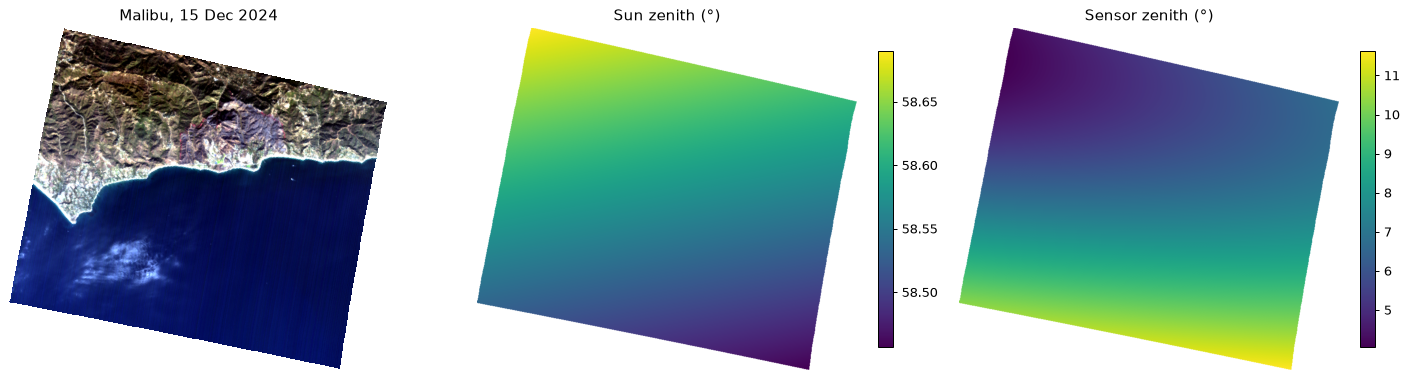

Sun zenith 58.5–58.7°, sensor zenith 4.0–11.6°
UAE (May): sun zenith ≈ 10.8°


In [15]:
sza = malibu.read_field("sun_zenith")
vza = malibu.read_field("sensor_zenith")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].imshow(malibu.rgb(mask=False)); axes[0].set_title("Malibu, 15 Dec 2024")
im = axes[1].imshow(sza, cmap="viridis"); plt.colorbar(im, ax=axes[1], fraction=0.035); axes[1].set_title("Sun zenith (°)")
im = axes[2].imshow(vza, cmap="viridis"); plt.colorbar(im, ax=axes[2], fraction=0.035); axes[2].set_title("Sensor zenith (°)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print(f"Sun zenith {np.nanmin(sza):.1f}–{np.nanmax(sza):.1f}°, sensor zenith {np.nanmin(vza):.1f}–{np.nanmax(vza):.1f}°")
print(f"UAE (May): sun zenith ≈ {np.nanmean(uae.read_field('sun_zenith', stride=8)):.1f}°")

In December the sun over Malibu is low (sun zenith ≈ 59°), so **topographic shading** in the Santa Monica Mountains is
strong. Sun zenith hardly varies within one scene, but between scenes (winter vs summer, Malibu vs UAE) it changes the
illumination a lot, which matters when you compare dates (notebook 30). The view angle varies a few degrees across the
strip and matters for directional effects (BRDF).

**Brightness normalisation** removes multiplicative illumination differences by scaling each spectrum:

- **vector normalisation**: $\rho' = \rho / \lVert\rho\rVert_2$ (the spectral angle is invariant to this)
- **mean (brightness) normalisation**: $\rho' = \rho / \bar\rho$

Let's compare shaded and sunlit chaparral with similar greenness (NDVI 0.5–0.65):

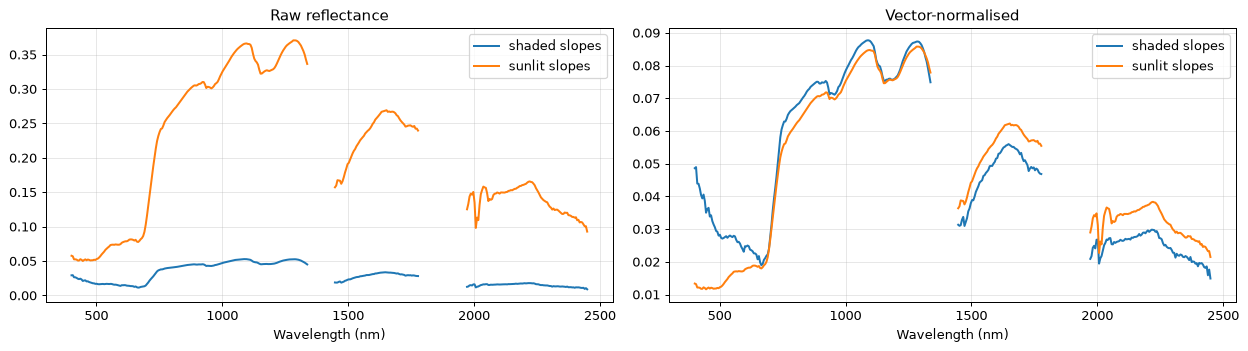

Brightness ratio sunlit/shaded (NIR): 6.7×
Euclidean distance raw: 3.73,  after vector normalisation: 0.16
Spectral angle: 9.3° (unchanged by normalisation)


In [16]:
mwin = (20, 250, 150, 700)
mc, mwl = malibu.read_cube(mwin)
nir, red = mc[hu.band_index(mwl, 860)], mc[hu.band_index(mwl, 665)]
sel = (hu.nd(nir, red) > 0.5) & (hu.nd(nir, red) < 0.65)
lo, hi = np.nanpercentile(nir[sel], [5, 95])
shaded = np.nanmedian(mc[:, sel & (nir < lo)], axis=1)
sunlit = np.nanmedian(mc[:, sel & (nir > hi)], axis=1)

def vnorm(s):
    return s / np.sqrt(np.nansum(s ** 2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for s, lab_ in [(shaded, "shaded slopes"), (sunlit, "sunlit slopes")]:
    hu.plot_spectrum(axes[0], mwl, s, lw=1.6, label=lab_)
    hu.plot_spectrum(axes[1], mwl, vnorm(s), lw=1.6, label=lab_)
axes[0].set_title("Raw reflectance"); axes[1].set_title("Vector-normalised")
for ax in axes: ax.set_xlabel("Wavelength (nm)"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

g = np.isfinite(shaded) & np.isfinite(sunlit)
print(f"Brightness ratio sunlit/shaded (NIR): {sunlit[hu.band_index(mwl, 860)] / shaded[hu.band_index(mwl, 860)]:.1f}×")
print(f"Euclidean distance raw: {np.linalg.norm(sunlit[g] - shaded[g]):.2f},  "
      f"after vector normalisation: {np.linalg.norm(vnorm(sunlit)[g] - vnorm(shaded)[g]):.2f}")
print(f"Spectral angle: {np.degrees(hu.spectral_angle(shaded[g][None], sunlit[g]))[0]:.1f}° (unchanged by normalisation)")

Normalisation removes most of the brightness difference, but not all of it. Shaded slopes are lit by **diffuse
skylight**, which is bluer than direct sunlight, so shading also changes the spectral *shape* a little. Sunlit and
shaded pixels also differ in vegetation composition (north- vs south-facing slopes). Brightness normalisation is a
useful first step; full topographic correction (e.g. the C-correction, which needs a DEM) is beyond this course.

## 8. Spatial preprocessing: cut, preview, share, export

Your project area is usually much smaller than a scene. Work on a **window** around it: it is faster, uses less memory
and keeps your analysis focused.

AOI window: (503, 703, 320, 520)


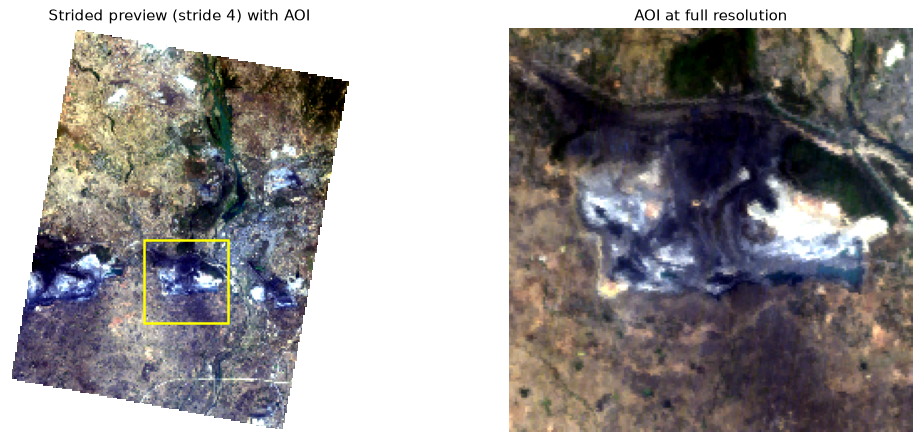

In [17]:
def window_from_lonlat(scene, lon, lat, half_size=100):
    # (row_start, row_stop, col_start, col_stop) centred on a lon/lat, clipped to the grid
    r, c = scene.lonlat_to_rowcol(lon, lat)
    r, c = int(r[0]), int(c[0])
    return (max(0, r - half_size), min(scene.shape[1], r + half_size),
            max(0, c - half_size), min(scene.shape[2], c + half_size))

# 1) quick strided preview of the whole scene (every 4th pixel) to find the area of interest
preview = korba.rgb(stride=4, mask=False)

# 2) a 200 × 200 pixel (6 × 6 km) window around the Kusmunda mine
aoi = window_from_lonlat(korba, 82.667, 22.3292, half_size=100)
print("AOI window:", aoi)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(preview)
r0, r1, c0, c1 = [v / 4 for v in aoi]
axes[0].add_patch(plt.Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, color="yellow", lw=2))
axes[0].set_title("Strided preview (stride 4) with AOI")
axes[1].imshow(korba.rgb(window=aoi)); axes[1].set_title("AOI at full resolution")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

**Share a subset.** `hu.write_subset` saves a window in the same HDF5 layout as the original, with reflectance stored as
int16 × 10 000 and compressed. It is small enough to email or put on a shared drive, and `hu.TanagerScene` reads it like
a full scene. Pixel (0, 0) of the subset is the top-left of the window.

In [18]:
small = window_from_lonlat(korba, 82.667, 22.3292, half_size=64)      # 128 × 128 pixels
sub_path = hu.write_subset(korba, OUT / f"{KORBA}_subset.h5", small)
sub = hu.TanagerScene(sub_path)
print(sub)
print(f"Subset size on disk: {sub_path.stat().st_size / 1e6:.1f} MB  (full scene: {korba.path.stat().st_size / 1e9:.2f} GB)")

a, _ = sub.read_cube((10, 20, 10, 20))
b_, _ = korba.read_cube((small[0] + 10, small[0] + 20, small[2] + 10, small[2] + 20))
print("Max difference subset vs original:", float(np.nanmax(np.abs(a - b_))), "(int16 rounding)")
print("Same georeferencing:", sub.transform() == korba.transform(small))

TanagerScene(20250219_053251_31_4001, 128×128 px, 426 bands)
Subset size on disk: 7.4 MB  (full scene: 1.23 GB)
Max difference subset vs original: 5.0008296966552734e-05 (int16 rounding)
Same georeferencing: True


**Export a GeoTIFF.** To use your result in QGIS, ArcGIS or a web map, export it as a **Cloud-Optimised GeoTIFF (COG)**:
a normal GeoTIFF with internal tiling and overviews that web tools can stream. Here we export a six-band subset plus the
Al–OH depth map, then reproject the depth map to geographic coordinates (EPSG:4326) with rasterio.

In [19]:
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling

bands_nm = [480, 560, 660, 860, 1650, 2200]
aoi_cube = np.stack([korba.read_band(nm, window=aoi) for nm in bands_nm])
cog_path = hu.save_geotiff(OUT / f"{KORBA}_aoi_6bands.tif", aoi_cube, korba.transform(aoi), korba.crs,
                           band_names=[f"{korba.wavelengths[korba.band_index(nm)]:.0f} nm" for nm in bands_nm])

cube_aoi, wl_aoi = korba.read_cube(aoi)
depth_aoi = hu.band_depth(wl_aoi, savgol_segments(cube_aoi, wl_aoi, 7), 2120, 2205, 2250).astype("float32")
depth_path = hu.save_geotiff(OUT / f"{KORBA}_aoi_AlOH_depth.tif", depth_aoi, korba.transform(aoi), korba.crs,
                             band_names=["AlOH_2205_depth"])

# reproject to EPSG:4326 (lon/lat)
with rasterio.open(depth_path) as src:
    t, w_, h_ = calculate_default_transform(src.crs, "EPSG:4326", src.width, src.height, *src.bounds)
    dst = np.full((h_, w_), np.nan, dtype="float32")
    reproject(rasterio.band(src, 1), dst, dst_transform=t, dst_crs="EPSG:4326", resampling=Resampling.bilinear,
              src_nodata=np.nan, dst_nodata=np.nan)
wgs_path = hu.save_geotiff(OUT / f"{KORBA}_aoi_AlOH_depth_wgs84.tif", dst, t, "EPSG:4326", band_names=["AlOH_2205_depth"])

for p in (cog_path, depth_path, wgs_path):
    with rasterio.open(p) as src:
        print(f"{p.name:48s} {src.count} band(s) {src.width}×{src.height}  {src.crs}  "
              f"pixel {src.res[0]:.6g}  {p.stat().st_size / 1e6:.2f} MB")

20250219_053251_31_4001_aoi_6bands.tif           6 band(s) 200×200  EPSG:32644  pixel 30  0.61 MB
20250219_053251_31_4001_aoi_AlOH_depth.tif       1 band(s) 200×200  EPSG:32644  pixel 30  0.12 MB
20250219_053251_31_4001_aoi_AlOH_depth_wgs84.tif 1 band(s) 210×195  EPSG:4326  pixel 0.000281028  0.15 MB


> ⚠️ Reprojection **resamples** the data. Do your spectral analysis on the original grid and reproject only final
> products, preferably with nearest-neighbour resampling for class maps and bilinear for continuous values.

## 9. Putting it together: a reusable `preprocess()` function

Copy this function into your project. It applies the choices discussed above and returns a report so you can document
them.

In [20]:
def preprocess(scene, window=None, stride=1, use_cloud_mask=True, extra_bad=(), smooth_window=0,
               normalize=None):
    # Read a window and apply the standard preprocessing chain of this course.
    #   use_cloud_mask : apply beta_cloud_mask/cirrus (inspect it first!)
    #   extra_bad      : extra (start, stop) nm ranges to drop, e.g. ((1440, 1490), (1995, 2020)) for water
    #   smooth_window  : Savitzky-Golay window length in bands (0 = no smoothing)
    #   normalize      : None, "vector" or "brightness"
    # Returns cube (bands, rows, cols), wavelengths, valid mask, report dict.
    cube, wl = scene.read_cube(window, bands="all", stride=stride, mask=False)
    keep = hu.good_band_mask(wl, scene.file_good_flags, extra_bad=extra_bad)
    cube, wl = cube[keep], wl[keep]
    valid = scene.valid_mask(window, stride, cloud=use_cloud_mask) & np.all(np.isfinite(cube), axis=0)
    cube[:, ~valid] = np.nan
    if smooth_window:
        cube = savgol_segments(cube, wl, smooth_window)
    if normalize == "vector":
        norm = np.sqrt(np.nansum(cube ** 2, axis=0, keepdims=True))
        cube = cube / np.where(norm > 0, norm, np.nan)
    elif normalize == "brightness":
        cube = cube / np.nanmean(cube, axis=0, keepdims=True)
    report = dict(scene=scene.scene_id, window=window, stride=stride, bands_kept=int(keep.sum()),
                  bands_total=int(len(keep)), valid_pixels=f"{valid.mean() * 100:.1f} %",
                  cloud_mask=use_cloud_mask, extra_bad=extra_bad, smoothing=smooth_window or None,
                  normalization=normalize)
    return cube, wl, valid, report

cube_p, wl_p, valid_p, rep = preprocess(korba, aoi, smooth_window=7)
for k, v in rep.items():
    print(f"{k:14s}: {v}")

scene         : 20250219_053251_31_4001
window        : (503, 703, 320, 520)
stride        : 1
bands_kept    : 352
bands_total   : 426
valid_pixels  : 100.0 %
cloud_mask    : True
extra_bad     : ()
smoothing     : 7
normalization : None


## ✏️ Your turn

**1. Inspect the Konya cloud mask.** The Konya scene reports ~1.2 % cloud. Overlay `beta_cloud_mask` on the true-colour
image. Are those real clouds? Look at the median spectrum of the flagged pixels.
<details><summary>Hint</summary>

`konya.masks()["cloud"]` gives the flag. Plot `konya.rgb(mask=False)` and overlay with `plt.contour(flag, levels=[0.5])`.
Real clouds are bright in the blue (> ~0.3) and spectrally flat.
</details>
<details><summary>Solution</summary>

```python
flag = konya.masks()["cloud"]
plt.figure(figsize=(8, 7)); plt.imshow(konya.rgb(mask=False)); plt.contour(flag, levels=[0.5], colors="r", linewidths=0.5)
cube_all, w_all = konya.read_cube(stride=2, cloud=False)
f2 = flag[::2, ::2]
fig, ax = plt.subplots(); hu.plot_spectrum(ax, w_all, np.nanmedian(cube_all[:, f2], axis=1), label="flagged")
hu.plot_spectrum(ax, w_all, np.nanmedian(cube_all[:, ~f2], axis=1), label="not flagged"); ax.legend()
# The flagged pixels are bright bare soils and roofs with soil-like spectra, not clouds.
```
</details>

**2. Choose a smoothing window.** For the Korba AOI, compute the Al–OH depth map with SG windows 5, 9, 15 and 25.
Plot the map noise (as in section 5.2) against the window length, and the median depth over the brightest spoil heaps.
Where does smoothing start to *reduce* the real feature depth?
<details><summary>Solution</summary>

```python
res = []
for wlen in [5, 9, 15, 25]:
    d = hu.band_depth(kwl, savgol_segments(kcube, kwl, wlen), 2120, 2205, 2250)
    patch = d[flat[0]:flat[1], flat[2]:flat[3]]
    res.append((wlen, np.nanstd(np.diff(patch, axis=1)) / np.sqrt(2), np.nanpercentile(d, 99)))
print(pd.DataFrame(res, columns=["window", "map noise", "p99 depth (spoil)"]))
# The map noise falls only slowly with window length, but the p99 depth (the real spoil signal) already drops at
# window 9 and roughly halves at 25: the window has become wider than the ~40 nm feature. Keep it at ≤ 7 bands here.
```
</details>

**3. Water-friendly band set.** Use `preprocess(malibu, ow, use_cloud_mask=False, extra_bad=((1440, 1490), (1995, 2020)))`.
How many complete ocean spectra do you get if you now set negatives to NaN? What if you also drop everything beyond 1000 nm?
<details><summary>Solution</summary>

```python
c, w, v, _ = preprocess(malibu, ow, use_cloud_mask=False, extra_bad=((1440, 1490), (1995, 2020)))
X = c.reshape(len(w), -1)
X = X[:, np.all(np.isfinite(X), axis=0)]
print(np.all(np.isfinite(np.where(X < 0, np.nan, X)), axis=0).mean())
vis = w < 1000
print(np.all(np.isfinite(np.where(X[vis] < 0, np.nan, X[vis])), axis=0).mean())
# Only ~4 % survive even with the extra ranges dropped (negatives remain near 1120–1130 and 2450 nm);
# restricted to < 1000 nm, ~80 % survive. For clear water, the SWIR carries essentially noise.
```
</details>

**4. Your project AOI.** Pick a lon/lat in the scene you will use for your project, cut a 128 × 128 window, save it with
`hu.write_subset`, and export an RGB + NIR COG. Open the COG in QGIS (or with `rasterio`) to check that it lands in the
right place.
<details><summary>Hint</summary>

Use `window_from_lonlat(scene, lon, lat, 64)`, then `hu.write_subset(scene, OUT / "my_subset.h5", window)` and
`hu.save_geotiff(path, np.stack([scene.read_band(nm, window=window) for nm in (640, 550, 460, 860)]), scene.transform(window), scene.crs)`.
</details>

**5. Carbonate map.** Adapt section 5.2 to map the **carbonate** feature (shoulders 2280 and 2400 nm, centre 2335 nm)
in the UAE scene. Remember to read the cube with `cloud=False`! Where is the carbonate signal strongest?
<details><summary>Solution</summary>

```python
ucube, uwl = uae.read_cube((400, 733, 0, 878), stride=2, cloud=False)
dep = hu.band_depth(uwl, savgol_segments(ucube, uwl, 7), 2280, 2335, 2400)
plt.imshow(dep, cmap="magma", vmin=0, vmax=0.1); plt.colorbar()
```
</details>

## Key takeaways

- Know your **processing level**: this course uses orthorectified **surface reflectance**; atmospheric correction
  leaves small residuals at gas absorption bands.
- **Inspect every quality mask** on top of an image. The beta cloud mask flags bright sabkha as cloud and misses
  thin cloud over the ocean. Use custom tests (e.g. SWIR over water) where needed.
- Drop bands with no signal: the flagged water-vapour bands (placeholder values), below 400 nm and beyond 2450 nm.
- Check noise on a **homogeneous** patch of your target. The uncertainty layer agrees with image-based estimates
  there; dark water has an SNR of only ~10–25 in the NIR/SWIR.
- Smooth with Savitzky-Golay **per contiguous segment**; derivatives and band depths need it.
- Don't set negative water reflectances to NaN blindly: drop the empty bands instead.
- Work on **windows**, share **subsets**, export **COGs**, and reproject only final products.

**For your project:** run the `preprocess()` function on your AOI and paste its report into your methods section.
Mask decisions and band choices are part of your method and affect your validation (notebook 21).

**References**: Savitzky & Golay (1964) *Anal. Chem.* 36; Gao et al. (2009) *Remote Sens. Environ.* 113 (atmospheric
correction of imaging spectroscopy); Thompson et al. (2018) *Remote Sens. Environ.* 216 (ISOFIT); Green et al. (1988)
*IEEE TGRS* 26 (MNF and shift-difference noise).

---
> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC · ESA WorldCover 2021 v200 — CC-BY 4.0